# Step 6: Where is the model unsure? (uncertainty maps, for the originality slide)
Idea from the organisers' Notebook 4 (section 4.3a), applied to OUR final method.

The model gives 4 probabilities per pixel. If they are spread out (e.g. 0.30 / 0.28 / 0.25 / 0.17) the model is unsure; if one is high (0.90) it is confident. We measure this with **entropy**: 0 bits = completely sure, 2 bits = a pure guess between 4 classes.

What this notebook shows:
1. Maps of Amsterdam (n = 25, the low-data prize setting): predicted class, uncertainty, right/wrong.
2. **Does the model know when it is wrong?** Accuracy for the most confident vs least confident pixels.
3. Practical message for a new city: label the uncertain areas first (future work: active learning).

Uses only the official saved models (read only). Writes `results/uncertainty_*.png` and `results/uncertainty_by_confidence.csv`. Run time: about 2 to 3 minutes (plus about 4 minutes for the optional Madrid part).

In [1]:
import importlib
import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pathlib import Path
from sklearn.metrics import f1_score, accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
import transfer_v3 as tv3
importlib.reload(tv3)

N_SHOW = 25                      # which saved Amsterdam model to map (25 = low-data prize)
DO_MADRID = True                 # also map Madrid with out-of-fold probabilities (~4 min)
CLASSES = tv3.CLASSES
CLASS_COLORS = ["#4393c3", "#2ca25f", "#fd8d3c", "#de2d26"]      # same colours as the organisers' notebooks
OUT = Path("results"); OUT.mkdir(exist_ok=True)

data = tv3.load_data(".")
s1 = joblib.load("models/stage1_madrid_model.joblib")
stage1 = {"rf": s1["rf"], "scaler_a": s1["scaler_amsterdam"]}
model = joblib.load(f"models/amsterdam_blend3_n{N_SHOW:03d}_seed42.joblib")

ya, ids = data["ya"], data["ids_a"].astype(np.int64)
qry = np.setdiff1d(np.arange(len(ya)), model["support_index"])         # never score the labelled pixels
P = tv3.predict_proba_blend3(model, stage1, data["Xa"])                 # all pixels (support = context)
P_s = tv3.smooth_proba(P, ids, alpha=0.5)                               # final method = with smoothing
P_q, y_q, ids_q = P_s[qry], ya[qry], ids[qry]
pred_q = CLASSES[P_q.argmax(1)]

def entropy(p):
    p = np.clip(p, 1e-12, 1)
    return -(p * np.log2(p)).sum(1)

H = entropy(P_q)
print(f"Amsterdam n={N_SHOW}: macro F1 on {len(qry):,} query pixels = {f1_score(y_q, pred_q, average='macro'):.4f}"
      f" | mean entropy {H.mean():.2f} bits (0 = sure, 2 = pure guess)")

Amsterdam n=25: macro F1 on 25,892 query pixels = 0.6639 | mean entropy 1.58 bits (0 = sure, 2 = pure guess)


## 1. Three maps of Amsterdam
Grey = no building pixel in the data, or one of the labelled support pixels (never scored). Left: what the model predicts. Middle: how unsure it is (dark = unsure). Right: where it is right (green) or wrong (red).

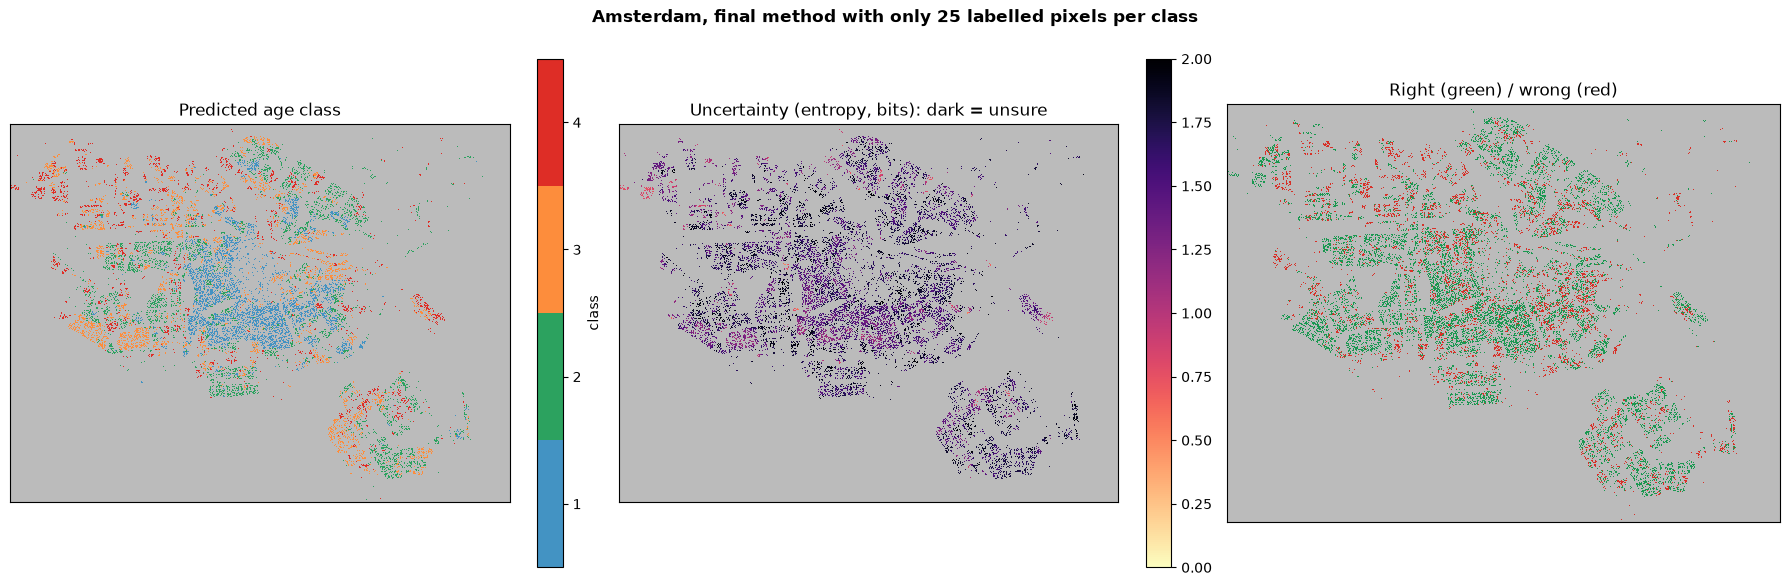

In [2]:
def grid(ids, values, fill=np.nan):
    x = ids[:, 0] - ids[:, 0].min(); y = ids[:, 1] - ids[:, 1].min()
    img = np.full((y.max() + 1, x.max() + 1), fill, dtype=float)
    img[y, x] = values
    return img[::-1]                                       # north up (py grows northwards in UTM)

def three_maps(ids, y_true, pred, H, title, fname):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    for ax in axes:
        ax.set_facecolor("#bbbbbb"); ax.set_xticks([]); ax.set_yticks([])
    im0 = axes[0].imshow(grid(ids, pred), cmap=ListedColormap(CLASS_COLORS), vmin=0.5, vmax=4.5, interpolation="nearest")
    axes[0].set_title("Predicted age class")
    cb = fig.colorbar(im0, ax=axes[0], ticks=[1, 2, 3, 4], fraction=0.046); cb.set_label("class")
    im1 = axes[1].imshow(grid(ids, H), cmap="magma_r", vmin=0, vmax=2, interpolation="nearest")
    axes[1].set_title("Uncertainty (entropy, bits): dark = unsure")
    fig.colorbar(im1, ax=axes[1], fraction=0.046)
    axes[2].imshow(grid(ids, (pred == y_true).astype(float)), cmap=ListedColormap(["#d73027", "#1a9850"]),
                   vmin=0, vmax=1, interpolation="nearest")
    axes[2].set_title("Right (green) / wrong (red)")
    fig.suptitle(title, fontweight="bold"); fig.tight_layout()
    fig.savefig(OUT / fname, dpi=150); plt.show()

three_maps(ids_q, y_q, pred_q, H, f"Amsterdam, final method with only {N_SHOW} labelled pixels per class",
           f"uncertainty_maps_amsterdam_n{N_SHOW:03d}.png")

## 2. Does the model know when it is wrong?
Pixels are split into 5 equal groups from most confident to least confident. If accuracy falls steadily from group 1 to group 5, the confidence is meaningful: a city could trust the confident predictions and send people to check only the unsure ones.

,city,group,pixels,min_confidence,max_confidence,accuracy,macro_f1
0,Amsterdam n=25,1,5179,0.634,0.919,0.859,0.833
1,Amsterdam n=25,2,5179,0.555,0.634,0.802,0.761
2,Amsterdam n=25,3,5178,0.489,0.555,0.696,0.645
3,Amsterdam n=25,4,5178,0.425,0.489,0.578,0.539
4,Amsterdam n=25,5,5178,0.256,0.425,0.428,0.387


Most confident 20%: accuracy 0.86 | least confident 20%: accuracy 0.43


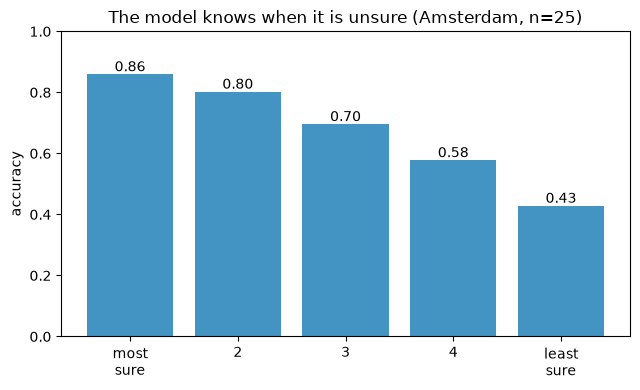

In [3]:
def by_confidence(P, y, label):
    conf = P.max(1)
    order = np.argsort(-conf)                              # most confident first
    groups = np.array_split(order, 5)
    rows = []
    for g, idx in enumerate(groups, 1):
        pr = CLASSES[P[idx].argmax(1)]
        rows.append({"city": label, "group": g, "pixels": len(idx),
                     "min_confidence": conf[idx].min().round(3), "max_confidence": conf[idx].max().round(3),
                     "accuracy": accuracy_score(y[idx], pr), "macro_f1": f1_score(y[idx], pr, average="macro")})
    return pd.DataFrame(rows)

conf_tab = by_confidence(P_q, y_q, f"Amsterdam n={N_SHOW}")
display(conf_tab.round(3))
top, bottom = conf_tab.iloc[0], conf_tab.iloc[-1]
print(f"Most confident 20%: accuracy {top.accuracy:.2f} | least confident 20%: accuracy {bottom.accuracy:.2f}")

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(conf_tab["group"], conf_tab["accuracy"], color="#4393c3")
for g, a in zip(conf_tab["group"], conf_tab["accuracy"]):
    ax.text(g, a + 0.01, f"{a:.2f}", ha="center")
ax.set_xticks(conf_tab["group"], ["most\nsure", "2", "3", "4", "least\nsure"])
ax.set_ylabel("accuracy"); ax.set_ylim(0, 1)
ax.set_title(f"The model knows when it is unsure (Amsterdam, n={N_SHOW})")
fig.tight_layout(); fig.savefig(OUT / f"uncertainty_vs_accuracy_amsterdam_n{N_SHOW:03d}.png", dpi=150); plt.show()

## 3. Optional: Madrid (out-of-fold probabilities)
Each Madrid pixel is predicted by a forest that did NOT see it (5-fold), so the map is honest.

Madrid out-of-fold macro F1 (smoothed) = 0.7296


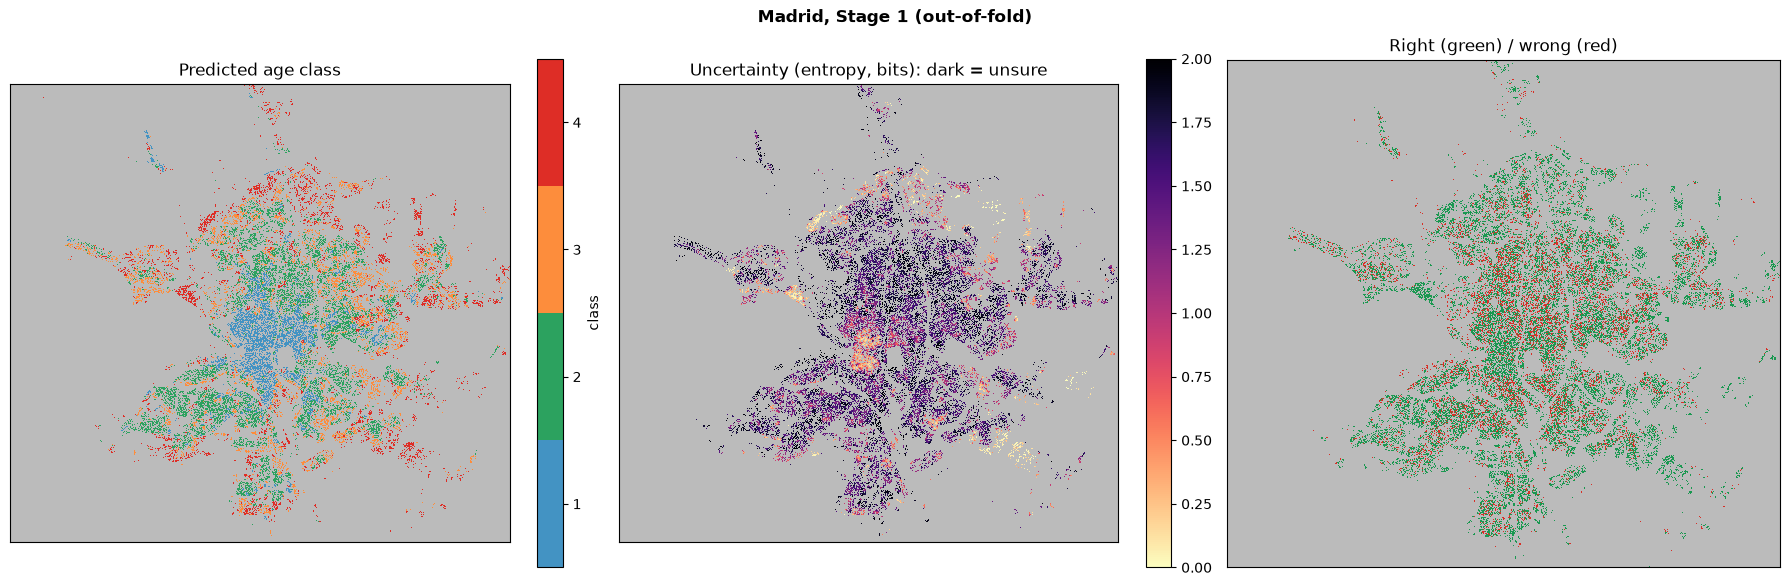

saved results/uncertainty_*.png and results/uncertainty_by_confidence.csv


In [4]:
if DO_MADRID:
    mad = pd.read_parquet("features_madrid_v3.parquet")
    ids_m = mad[["px_key", "py_key"]].to_numpy(np.int64)
    Xm, ym = data["Xm"], data["ym"]
    P_m = np.zeros((len(ym), 4))
    for tr, va in StratifiedKFold(5, shuffle=True, random_state=tv3.SEED).split(Xm, ym):
        P_m[va] = RandomForestClassifier(**tv3.RF_PARAMS).fit(Xm[tr], ym[tr]).predict_proba(Xm[va])
    P_m = tv3.smooth_proba(P_m, ids_m, alpha=0.5)
    pred_m = CLASSES[P_m.argmax(1)]
    print(f"Madrid out-of-fold macro F1 (smoothed) = {f1_score(ym, pred_m, average='macro'):.4f}")
    three_maps(ids_m, ym, pred_m, entropy(P_m), "Madrid, Stage 1 (out-of-fold)", "uncertainty_maps_madrid.png")
    conf_tab = pd.concat([conf_tab, by_confidence(P_m, ym, "Madrid out-of-fold")], ignore_index=True)

conf_tab.round(4).to_csv(OUT / "uncertainty_by_confidence.csv", index=False)
print("saved results/uncertainty_*.png and results/uncertainty_by_confidence.csv")